# Trade-off between average Pauli weight and quantum Fourier entropy

This notebook reproduces the **red curve only** in the accompanying schematic figure.
Other annotations and graphical elements in the published figure were added separately.

For $n=10$ and $a\geq1$, we evaluate

$$
W(O) = \frac{3a}{1+3a}n,
$$

$$
\frac{S_a(O)}{\lambda} = \left\{ n\log_a(1+3a) -\frac{3a}{1+3a}n \right\} / \lambda, \;\; \lambda = \frac{\log4}{\log a}.
$$

The expression at $a=1$ is evaluated by its continuous extension.
The curve is sampled at discrete points and connected by straight segments.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# A sufficiently large upper bound for visualizing the limiting behavior.
A_VALUES = np.geomspace(1, 1e5, 1000)
N_QUBITS = 10


In [2]:
def tradeoff_coordinates(a, n):
    """Return W(O) and S_a(O)/lambda for the chosen a values."""
    weight = n* (3*a)/(1+3*a)
    scaled_entropy = ( n*np.log(1+3*a) - weight*np.log(a) ) / np.log(4)
    
    return weight, scaled_entropy

w_values, s_values = tradeoff_coordinates(A_VALUES, N_QUBITS)

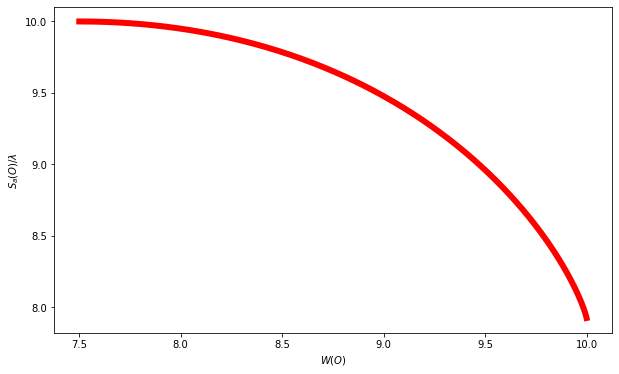

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(w_values, s_values, color="red", linewidth=6)
ax.set_xlabel(r"$W(O)$")
ax.set_ylabel(r"$S_a(O)/\lambda$")

output_path = Path("ws_curve.pdf")
fig.savefig(output_path, bbox_inches="tight")
plt.show()

# Reproducibility notes

- Requires Python with NumPy and Matplotlib.
- Run the cells from top to bottom. The resulting `ws_curve.pdf` contains only the red curve and basic axis labels, **not** the complete schematic figure.
- No random numbers or external datasets are used.